# データサイエンス実践A 第11講：総復習・伝わるグラフ
### 新潟大学 創生学部（2026年度）
**講義日：2026年11月13日（金）**

1. ここまでに習った**7種類のグラフ**を、同じ Excel から1つずつ描き直す。
1. 第８講の**複合グラフ**（棒＋折れ線、左右の y 軸）を描き直す。
1. **誤解を招くグラフ**の例を正しい描き方と並べて見て、**伝わるグラフ**のチェックリストを確かめる（AT）。
1. 第２回課題（締切 11/16）で困っているところは、この時間に質問する。
1. **よくあるエラー**の表で、自分がつまずいたエラーを確かめる。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[AE. グラフの型の総復習](#AE.-グラフの型の総復習)**
- [AE-0 グラフの型の一覧](#AE-0-グラフの型の一覧)
- [AE-1 折れ線グラフ](#AE-1-折れ線グラフ)
- [AE-2 散布図](#AE-2-散布図)
- [AE-3 棒グラフ](#AE-3-棒グラフ)
- [AE-4 ヒストグラム](#AE-4-ヒストグラム)
- [AE-5 箱ひげ図](#AE-5-箱ひげ図)
- [AE-6 円グラフ](#AE-6-円グラフ)
- [AE-7 エラーバー](#AE-7-エラーバー)
- [AE-8 複合グラフ（棒＋折れ線）](#AE-8-複合グラフ（棒＋折れ線）)
- [AE-9 共通の指定](#AE-9-共通の指定)

**[AT. 伝わるグラフ・誤解を招くグラフ](#AT.-伝わるグラフ・誤解を招くグラフ)**
- [AT-1 縦軸を途中から始めた棒グラフ](#AT-1-縦軸を途中から始めた棒グラフ)
- [AT-2 項目が多すぎる円グラフ](#AT-2-項目が多すぎる円グラフ)
- [AT-3 第３回課題に向けたチェックリスト](#AT-3-第３回課題に向けたチェックリスト)

**[AF. よくあるエラーと対処](#AF.-よくあるエラーと対処)**

**[AG. 発展（できる人だけ）](#AG.-発展（できる人だけ）)**
- [AG-1 1枚に並べる](#AG-1-1枚に並べる)
- [AG-2 ヒストグラムに正規分布の曲線を重ねる](#AG-2-ヒストグラムに正規分布の曲線を重ねる)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回は、画像や記号をマーカーにした**遊び心のあるグラフ**を描いた
- `plt.subplot(縦の数, 横の数, 何番目)` で、複数のグラフを並べた
- 第２回課題の締切は 11/16（月）。今日の総復習に、課題で使うグラフ（円・箱ひげ図・複合グラフ・エラーバー）も入っている

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

---
# AE. グラフの型の総復習

## AE-0 グラフの型の一覧

困ったら、この表の形を写してデータを入れ替える。

| グラフ | 使う場面 | 書き方 | 習った回 |
|---|---|---|---|
| 折れ線 | 時間の流れ・順番に意味がある | `plt.plot(x, y)` | 第３講 |
| 散布図 | 2つの量の関係 | `plt.scatter(x, y)` | 第４講 |
| 棒 | 項目ごとの大きさ比べ | `plt.bar(項目, 値)` | 第６講 |
| ヒストグラム | 1つの量の分布 | `plt.hist(データ, bins=10)` | 第９講 |
| 箱ひげ図 | グループごとのばらつき比べ | `plt.boxplot([データ1, データ2])` | 第７講 |
| 円 | 全体に対する割合 | `plt.pie(値, labels=名前)` | 第６講 |
| エラーバー | 平均とばらつき | `plt.errorbar(x, 平均, yerr=標準偏差)` | 第９講 |

- 2つのグラフを1枚に重ねる**複合グラフ**（第８講）は、AE-8 で復習する
- 以下では、7種類を `dsa2026data.xlsx` から1つずつ描く。どれも**Excel を読む → 列を取り出す → 描く**の3段

In [2]:
df_acc = pd.read_excel('dsa2026data.xlsx', sheet_name='accident')
df_wb = pd.read_excel('dsa2026data.xlsx', sheet_name='worldbank')
df_exam = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
df_rain = pd.read_excel('dsa2026data.xlsx', sheet_name='降水量')
df_tip = pd.read_excel('dsa2026data.xlsx', sheet_name='tip_data')

- シートを5つ読み込んだ。中身は `df_acc.head()` のように確かめられる

## AE-1 折れ線グラフ

- 交通事故件数の移り変わり（年が順番に並ぶ → 折れ線）

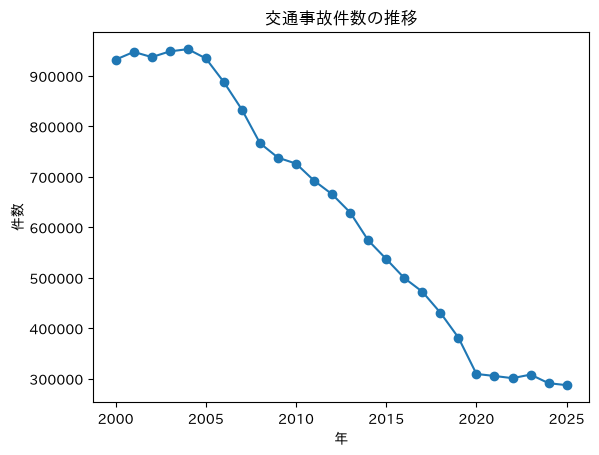

In [3]:
plt.plot(df_acc['年'], df_acc['交通事故件数'], marker='o')
plt.title('交通事故件数の推移')
plt.xlabel('年')
plt.ylabel('件数')
plt.show()

## AE-2 散布図

- 一人あたりGDPと平均寿命の関係（2つの量 → 散布図）。GDP は差が大きいので `plt.xscale('log')`（第８講）

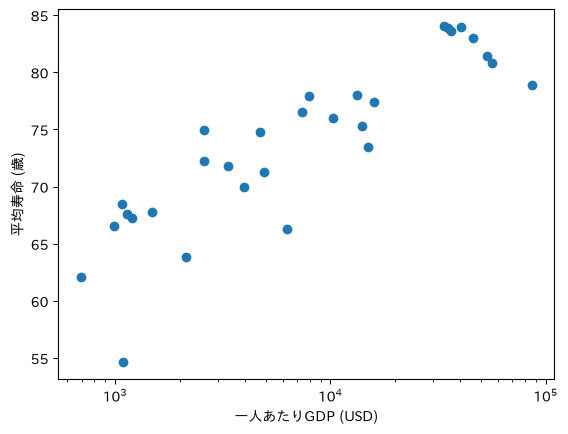

In [4]:
plt.scatter(df_wb['一人あたりGDP'], df_wb['出生時平均寿命'])
plt.xscale('log')
plt.xlabel('一人あたりGDP (USD)')
plt.ylabel('平均寿命 (歳)')
plt.show()

## AE-3 棒グラフ

- 月ごとの降水量（項目ごとの大きさ → 棒）

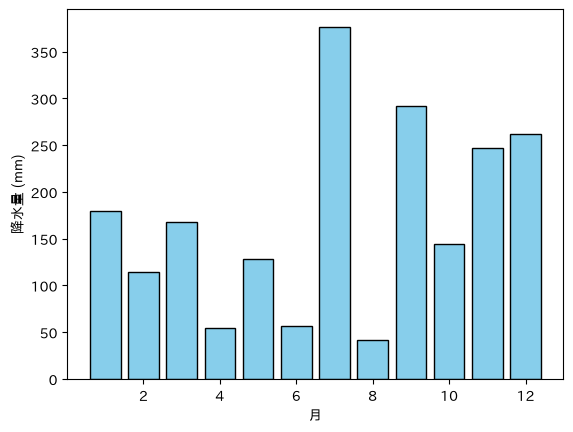

In [5]:
plt.bar(df_rain['月'], df_rain['降水量'], color='skyblue', edgecolor='k')
plt.xlabel('月')
plt.ylabel('降水量 (mm)')
plt.show()

## AE-4 ヒストグラム

- 数学の点数の分布（1つの量の分布 → ヒストグラム）。第９講 AA の復習
- `bins=10, range=(0, 100)` で 0〜100 点の10点刻みになる

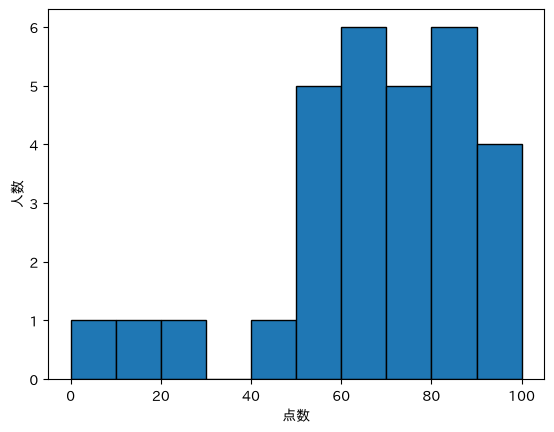

In [6]:
plt.hist(df_exam['数学'], bins=10, range=(0, 100), edgecolor='k')
plt.xlabel('点数')
plt.ylabel('人数')
plt.show()

- 補足：2つのグループを比べるときは、`plt.hist` を2回書いて `alpha=0.5` で重ねる（第９講 AA-6）。`bins=` と `range=` は2つとも同じ値にする

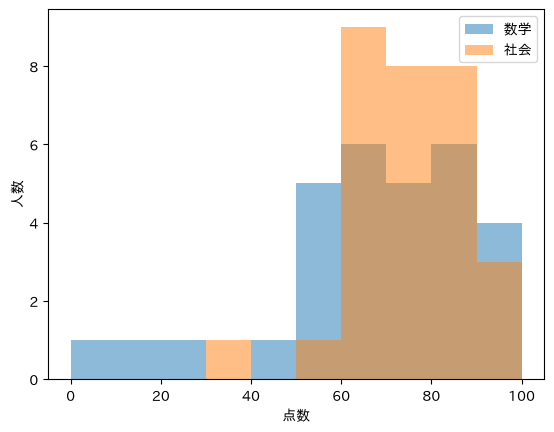

In [7]:
plt.hist(df_exam['数学'], bins=10, range=(0, 100), alpha=0.5, label='数学')
plt.hist(df_exam['社会'], bins=10, range=(0, 100), alpha=0.5, label='社会')
plt.xlabel('点数')
plt.ylabel('人数')
plt.legend()
plt.show()

## AE-5 箱ひげ図

- 5教科のばらつき比べ（グループごとのばらつき → 箱ひげ図）

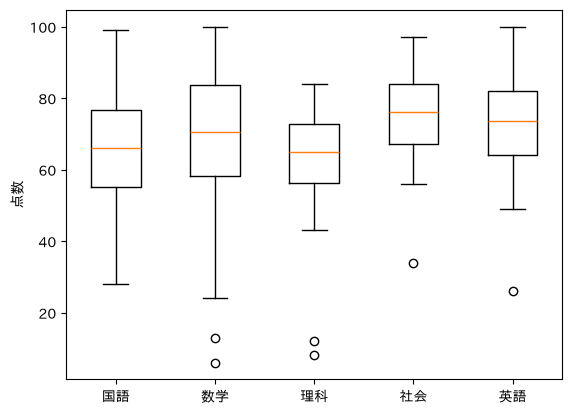

In [8]:
plt.boxplot([df_exam['国語'], df_exam['数学'], df_exam['理科'], df_exam['社会'], df_exam['英語']])
plt.xticks([1, 2, 3, 4, 5], ['国語', '数学', '理科', '社会', '英語'])
plt.ylabel('点数')
plt.show()

- 第７講 S-7 と同じ形。`[ ]` の中に列を並べると、左から順に箱が並ぶ
- 補足：`subjects = ['国語', '数学', '理科', '社会', '英語']` と列名のリストを作っておけば、`plt.boxplot(df_exam[subjects])` と短く書ける（`df[列名のリスト]` で、複数の列をまとめて取り出せる）

## AE-6 円グラフ

- チップのデータの曜日の割合（全体に対する割合 → 円）。`value_counts()` で曜日ごとの件数を数える（第６講）

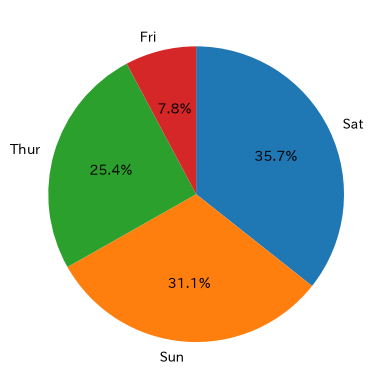

In [9]:
count = df_tip['day'].value_counts()
plt.pie(count, labels=count.index, startangle=90, counterclock=False, autopct='%.1f%%')
plt.show()

## AE-7 エラーバー

- 5教科の平均と標準偏差（平均とばらつき → エラーバー）

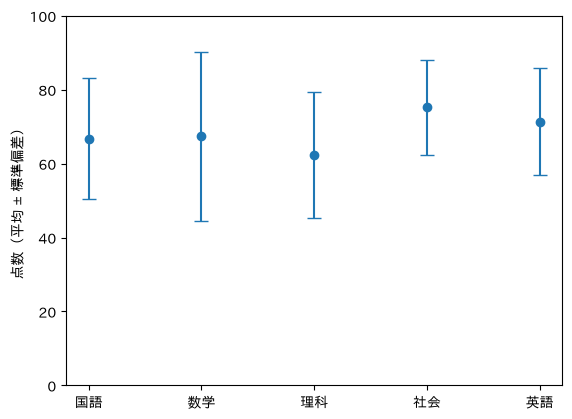

In [10]:
subjects = ['国語', '数学', '理科', '社会', '英語']
means = [np.mean(df_exam['国語']), np.mean(df_exam['数学']), np.mean(df_exam['理科']),
         np.mean(df_exam['社会']), np.mean(df_exam['英語'])]
stds = [np.std(df_exam['国語']), np.std(df_exam['数学']), np.std(df_exam['理科']),
        np.std(df_exam['社会']), np.std(df_exam['英語'])]

plt.errorbar(subjects, means, yerr=stds, fmt='o', capsize=5)
plt.ylim(0, 100)
plt.ylabel('点数（平均 ± 標準偏差）')
plt.show()

## AE-8 複合グラフ（棒＋折れ線）

- 第８講 Z の復習。単位や大きさが違う2つの量（件数と人数、mm と ℃ など）を1枚に描くときは、`plt.twinx()` で**右にもう1本 y 軸**を作る
- `plt.twinx()` の**前**に書いたものは左の y 軸、**後**に書いたものは右の y 軸に付く。横軸の設定と `title` は前に書く
- 交通事故件数（棒・左の軸）と死者数（折れ線・右の軸）を重ねる

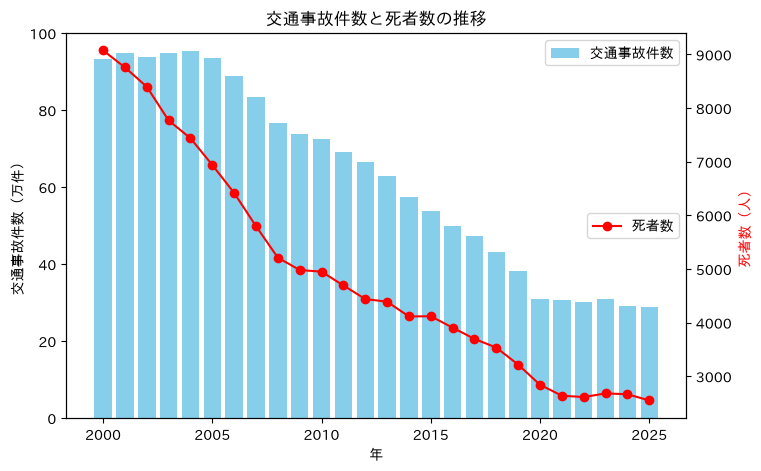

In [11]:
plt.figure(figsize=(8, 5))

# 左の y 軸（棒グラフ）と、両方に共通する設定
plt.bar(df_acc['年'], df_acc['交通事故件数'] / 10000, color='skyblue', label='交通事故件数')
plt.ylabel('交通事故件数（万件）')
plt.xlabel('年')
plt.title('交通事故件数と死者数の推移')
plt.legend(loc='upper right')

# 右の y 軸を追加（折れ線グラフ）
plt.twinx()
plt.plot(df_acc['年'], df_acc['死者数'], color='r', marker='o', label='死者数')
plt.ylabel('死者数（人）', color='r')
plt.legend(loc='center right')

plt.show()

- 件数は大きいので `/ 10000` で万件にした（そのままだと軸の上に `1e6` と出る）
- 凡例は左右で別々になるので、`loc='upper right'` と `loc='center right'` のように、グラフと重ならない位置に分ける
- 右の軸の名前を線と同じ色（`color='r'`）にすると、どちらの軸か分かりやすい

### 使ってみよう
- 第８講 Z-2 のひな形を写して、`降水量` シートで降水量（棒）と気温（折れ線）の雨温図を描いてみよう

In [12]:
# ここで試してみよう

- ヒストグラムと折れ線も重ねられる。下は、数学の点数のヒストグラム（左の軸）に、**累積の割合**（その点数までに全体の何 % が入るか）の折れ線（右の軸）を重ねた例

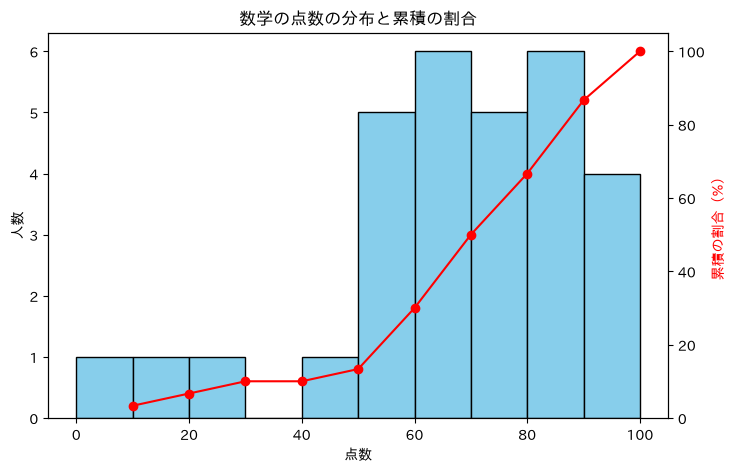

In [13]:
plt.figure(figsize=(8, 5))

# 左の y 軸（ヒストグラム）と、両方に共通する設定
counts, edges, patches = plt.hist(df_exam['数学'], bins=10, range=(0, 100), color='skyblue', edgecolor='k')
plt.xlabel('点数')
plt.ylabel('人数')
plt.title('数学の点数の分布と累積の割合')

# 右の y 軸を追加（累積の割合の折れ線）
plt.twinx()
ruiseki = np.cumsum(counts) / len(df_exam['数学']) * 100
plt.plot(edges[1:], ruiseki, color='r', marker='o')
plt.ylabel('累積の割合（%）', color='r')
plt.ylim(0, 105)

plt.show()

- `plt.hist` は、描くだけでなく [1] 区間ごとの人数 [2] 区間の境目 [3] 棒の部品 の3つを返す（第９講 AC-3）。`counts, edges, patches =` のように、変数を `,` で区切って受け取る
- `np.cumsum(counts)` は、先頭から順に足していった値（累積和）。全体の人数 `len(...)` で割って100倍すると % になる
- `edges[1:]` は、境目のリストから先頭を除いたもの＝各区間の右端。「その点数まで」の位置に点を打つ
- 折れ線が急に上がるところに人が集まっている。50% の線を横切るあたりが、ちょうど真ん中の点数

## AE-9 共通の指定

| やりたいこと | 書き方 | 習った回 |
|---|---|---|
| Excel を読む | `df = pd.read_excel('ファイル名', sheet_name='シート名')` | 第５講 |
| 列を取り出す | `df['列名']` | 第５講 |
| 大きさ | `plt.figure(figsize=(8, 5))` を最初に | 第３講 |
| 文字 | `plt.title`、`plt.xlabel`、`plt.ylabel` | 第３講 |
| 凡例 | `label=` ＋ `plt.legend()` | 第３講 |
| 範囲 | `plt.xlim`、`plt.ylim` | 第３講 |
| 補助線 | `plt.axhline(y=値)`、`plt.axvline(x=値)` | 第４講 |
| 注釈 | `plt.text(x, y, '文字')` | 第８講 |
| 点・棒ごとの色 | 散布図は `c=色のリスト`、棒グラフは `color=色のリスト` | 第４講・第６講 |
| 右にもう1本 y 軸 | `plt.twinx()`（前に書いたものは左、後に書いたものは右の軸） | 第８講 |
| 保存 | `plt.savefig('名前.png', dpi=300)` を `plt.show()` の前に | 第５講 |

### 使ってみよう
- 上の7つから1つ選び、**別の列**で描き直してみよう（例：折れ線を `'死者数'` に、ヒストグラムを `'英語'` に）
- 色・タイトル・軸の名前を付け、`plt.savefig` で保存してみよう

In [14]:
# ここで試してみよう

---
# AT. 伝わるグラフ・誤解を招くグラフ

ここまでのグラフを、「見る人に正しく伝わるか」という目で見直す。よくある失敗を、正しい描き方と並べて見る（並べ方は第10講 AI-1 の `plt.subplot`）。

## AT-1 縦軸を途中から始めた棒グラフ

- 左は 90 から始めているので、A と B の差が何倍にも見える。**棒グラフの縦軸は 0 から**

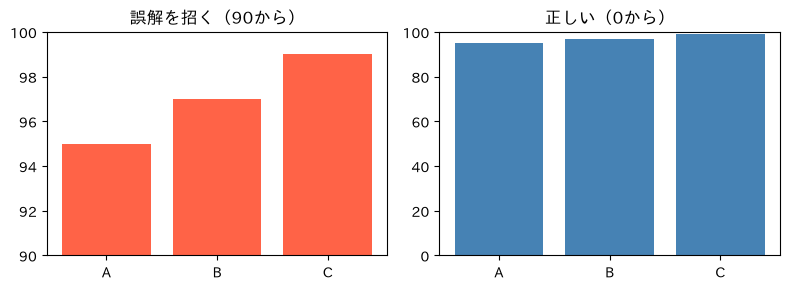

In [15]:
names = ['A', 'B', 'C']
values = [95, 97, 99]

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
plt.bar(names, values, color='tomato')
plt.ylim(90, 100)
plt.title('誤解を招く（90から）')

plt.subplot(1, 2, 2)
plt.bar(names, values, color='steelblue')
plt.ylim(0, 100)
plt.title('正しい（0から）')
plt.tight_layout()
plt.show()

- 棒グラフは「棒の長さ」で大きさを比べる。途中から始めると、長さの比が実際の値の比と合わなくなる
- 折れ線グラフは「変化」を見るので、途中から始めてもよい（ただし軸の数字ははっきり書く）

## AT-2 項目が多すぎる円グラフ

- 項目が多いと、小さい扇形が読めなくなる。**5つくらいまで**にして、残りは「その他」にまとめる

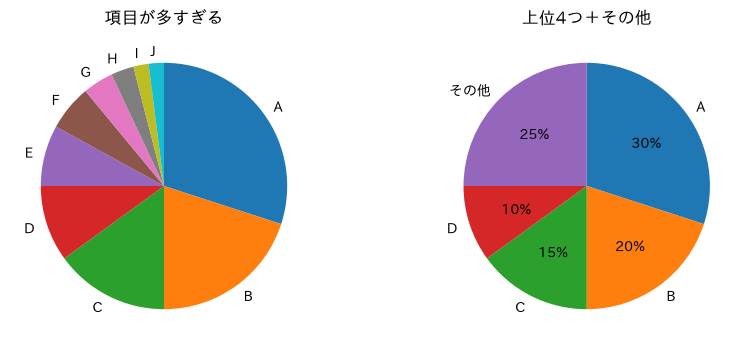

In [16]:
names = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']
values = [30, 20, 15, 10, 8, 6, 4, 3, 2, 2]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.pie(values, labels=names, startangle=90, counterclock=False)
plt.title('項目が多すぎる')

plt.subplot(1, 2, 2)
plt.pie(values[:4] + [sum(values[4:])], labels=names[:4] + ['その他'],
        autopct='%1.0f%%', startangle=90, counterclock=False)
plt.title('上位4つ＋その他')
plt.show()

- `values[:4]` は前から4つ、`values[4:]` は5つ目から最後まで（リストの切り出し）。`sum()` で合計する

## AT-3 第３回課題に向けたチェックリスト

| よくある失敗 | どうする |
|---|---|
| 棒グラフの縦軸が 0 から始まっていない | `plt.ylim(0, …)` |
| 立体（3D）の円グラフ | 手前が大きく見える。平らな円グラフか棒グラフにする |
| 項目が多すぎる円グラフ | 5つくらいまで。残りは「その他」にまとめる |
| 軸の名前・単位がない | `plt.xlabel`・`plt.ylabel` に単位まで書く（例：`'降水量 (mm)'`） |
| 色が多すぎる・赤と緑で区別している | 色は意味のあるところだけ。赤と緑は見分けにくい人がいるので、青とオレンジなどにする |
| 凡例がなく、どの線が何か分からない | `label=` ＋ `plt.legend()` |
| 文字が小さくて読めない | `fontsize=14` など。スライドに貼るなら大きめに |
| データの出どころが書いていない | 図の下や説明文に「出典：e-Stat ○○統計」などと書く |
| 画像やイラストでデータが読みにくい | 遊び心（第10講 AH）は**データが読める範囲で** |

> **第３回課題に向けて**：自分のグラフで、この表を1つずつ確かめる

---
# AF. よくあるエラーと対処

エラーが出たら、**いちばん最後の行**を見る。

| エラー（最後の行） | よくある原因 | 対処 |
|---|---|---|
| `SyntaxError` | `'` や `)` の閉じ忘れ、`:` の付け忘れ | 指された行の前後を見る |
| `IndentationError` | for・if の下の字下げがずれている | スペース4つにそろえる |
| `NameError` | 変数名の打ち間違い／上のセルを実行していない | 上のセルから実行し直す |
| `ModuleNotFoundError` | ライブラリが入っていない | `pip install japanize-matplotlib` など |
| `FileNotFoundError` | Excel が notebook と別のフォルダにある／名前の打ち間違い | notebook と同じ場所（いつもの場所）に置く |
| `KeyError` | `df['列名']` の列名が違う（空白・全角半角） | `df.head()` で列名を確かめる |
| `ValueError: x and y must have same first dimension` | x と y の個数が違う | `len()` で数をそろえる |
| 日本語が □ になる | `import japanize_matplotlib` を忘れた | import のセルを実行する |
| 保存した画像が白紙 | `savefig` を `show` の後に書いた | `savefig` を `show` の前に |

- エラーの文をそのまま AI や検索に貼ると、原因が分かることが多い。ただし、直したコードは**自分で読んで**から使う

---
# AG. 発展（できる人だけ）

## AG-1 1枚に並べる

- `plt.subplot(縦の数, 横の数, 番号)` で、1枚の図に複数のグラフを並べる（第10講 AI-1）

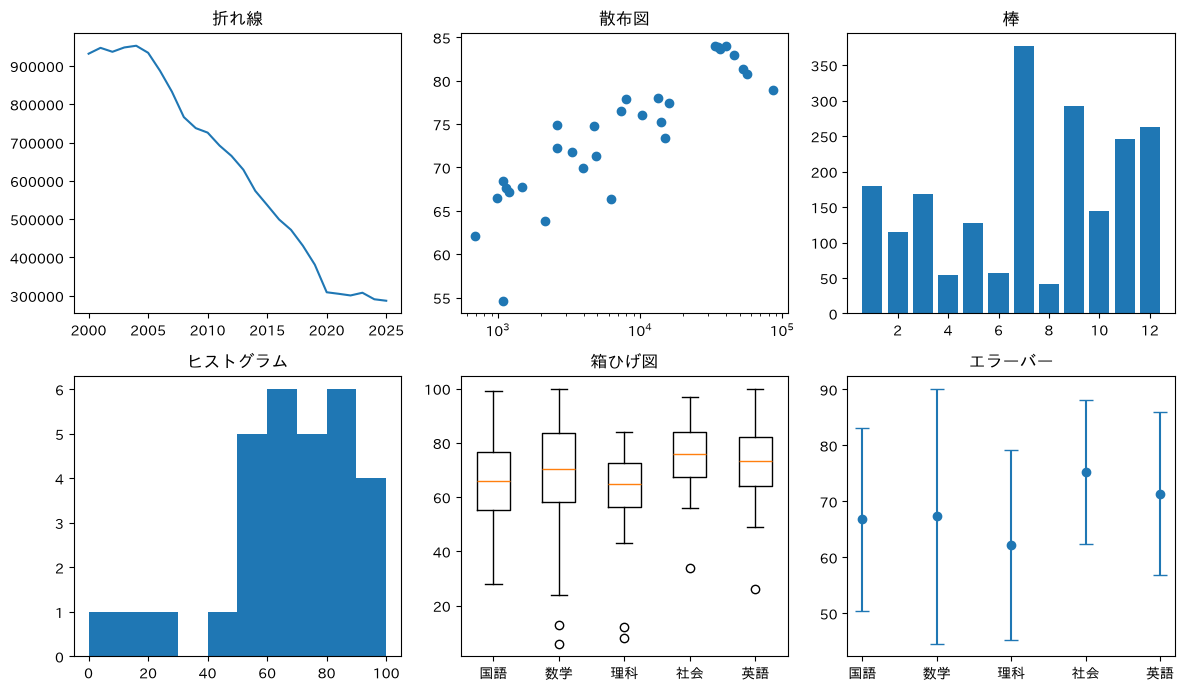

In [17]:
plt.figure(figsize=(12, 7))

plt.subplot(2, 3, 1)
plt.plot(df_acc['年'], df_acc['交通事故件数'])
plt.title('折れ線')

plt.subplot(2, 3, 2)
plt.scatter(df_wb['一人あたりGDP'], df_wb['出生時平均寿命'])
plt.xscale('log')
plt.title('散布図')

plt.subplot(2, 3, 3)
plt.bar(df_rain['月'], df_rain['降水量'])
plt.title('棒')

plt.subplot(2, 3, 4)
plt.hist(df_exam['数学'], bins=10, range=(0, 100))
plt.title('ヒストグラム')

plt.subplot(2, 3, 5)
plt.boxplot([df_exam['国語'], df_exam['数学'], df_exam['理科'], df_exam['社会'], df_exam['英語']])
plt.xticks([1, 2, 3, 4, 5], subjects)
plt.title('箱ひげ図')

plt.subplot(2, 3, 6)
plt.errorbar(subjects, means, yerr=stds, fmt='o', capsize=5)
plt.title('エラーバー')

plt.tight_layout()
plt.show()

## AG-2 ヒストグラムに正規分布の曲線を重ねる

- `density=True` を付けると、ヒストグラムの縦軸が人数から**割合（密度）**に変わる（棒の面積の合計が1になる）
- 同じ平均・標準偏差の**正規分布**の曲線を重ねると、データが「釣り鐘型」にどれくらい近いかが分かる
- 曲線の高さは `scipy` の `norm.pdf(x, 平均, 標準偏差)` で計算する

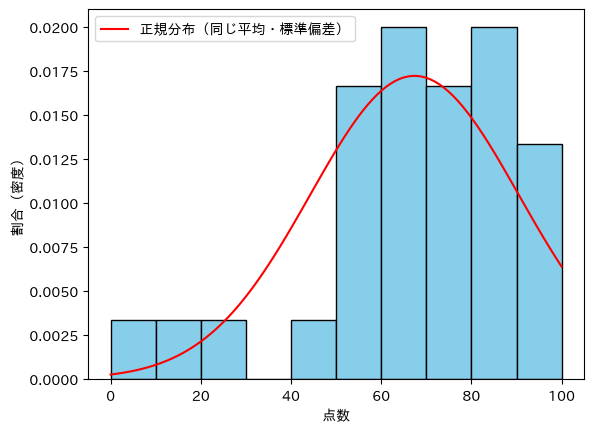

In [18]:
from scipy.stats import norm

math = df_exam['数学']
plt.hist(math, bins=10, range=(0, 100), density=True, color='skyblue', edgecolor='k')

x = list(range(0, 101))
plt.plot(x, norm.pdf(x, math.mean(), math.std()), color='r', label='正規分布（同じ平均・標準偏差）')

plt.xlabel('点数')
plt.ylabel('割合（密度）')
plt.legend()
plt.show()

- `x = list(range(0, 101))` は 0〜100 の整数のリスト（`range` は第９講 AA-4 で使った。`list( )` でリストにする）。曲線は、この101個の点を折れ線でつないだもの
- `density=True` を付けないと、縦軸が人数のままなので、曲線が低すぎて床にはりついて見える
- `'数学'` を他の教科に変えて、釣り鐘型に近い教科・遠い教科を探してみよう

---
# まとめ

- グラフは「何を見せたいか」で選ぶ：**移り変わり**→折れ線、**関係**→散布図、**大きさ比べ**→棒、**分布**→ヒストグラム、**ばらつき比べ**→箱ひげ図、**割合**→円、**平均とばらつき**→エラーバー
- どのグラフも **Excel を読む → 列を取り出す → 描く** の3段
- 単位や大きさの違う2つの量は、**複合グラフ**で重ねる。`plt.twinx()` の前が左の y 軸、後が右の y 軸
- 棒グラフの縦軸は **0 から**。円グラフの項目は **5つくらいまで**。第３回課題では、AT-3 のチェックリストで自分のグラフを確かめる
- エラーは**最後の行**を見て、AF の表で原因を探す

次回（第12講）は**第２回課題の解説**と、同じ処理をくり返す **for 文**。